# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_splits_seq_fit_predict
from src.evaluation.baseline import PreviousValueRegressor

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True
DATA_FREQUENCY = 'H' if HOURLY else '5min'

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.01 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(554, 43), y=(554,)
First valid split shape: X=(573, 43), y=(573,)

Memory usage:
Train: 5.34 MB
Valid: 1.24 MB
Test: 0.36 MB
Total: 6.95 MB


# Model evaluation

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
update_freq = "1H"
baseline = PreviousValueRegressor()

baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_splits_seq_fit_predict(
    model=baseline,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2600
	MAE: 0.1511
	MAPE: 17.9629%
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0603
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3599
	MAE: 0.1468
	MAPE: 0.9834%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9995
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.7713
	MAE: 0.4562
	MAPE: 0.9324%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2667
	MAE: 0.1528
	MAPE: 24.0071%
	Directional Accuracy: 37.8709%
	First-Diff Correlation: 0.2342
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.5059
	MAE: 0.1976
	MAPE: 1.6414%
	Directional Accuracy: 91.6667%
	First-Diff Correlation: 0.9989
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 1.2948
	MAE: 0.9985
	MAPE: 0.9153%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
---------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2371
	MAE: 0.1401
	MAPE: 29.4535%
	Directional Accuracy: 36.9983%
	First-Diff Correlation: 0.0275
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.2528
	MAE: 0.0946
	MAPE: 1.5852%
	Directional Accuracy: 95.8333%
	First-Diff Correlation: 0.9994
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.5645
	MAE: 0.2719
	MAPE: 1.0851%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
---------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1825
	MAE: 0.0849
	MAPE: 15.2001%
	Directional Accuracy: 43.6735%
	First-Diff Correlation: 0.1965
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 0.3760
	MAE: 0.1296
	MAPE: 1.1665%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9987
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 0.9021
	MAE: 0.6420
	MAPE: 1.5335%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

#### Results

In [8]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2448 ± 0.0277
	MAE: 0.1376 ± 0.0219
	MAPE: 26.4192% ± 7.0540%
	Dir Accuracy: 36.9306% ± 3.1016%
	First-Diff Correlation: 0.0973 ± 0.1369
Daily Metrics:
	RMSE: 0.3645 ± 0.0980
	MAE: 0.1432 ± 0.0356
	MAPE: 1.7594% ± 0.7643%
	Dir Accuracy: 95.5159% ± 3.5833%
	First-Diff Correlation: 0.9987 ± 0.0013
Weekly Metrics:
	RMSE: 0.8183 ± 0.2316
	MAE: 0.5445 ± 0.2251
	MAPE: 1.4698% ± 1.1637%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 1.0007 ± 0.5640
	MAE: 0.9953 ± 0.5605
	MAPE: 0.4541% ± 0.3762%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


#### Validation plots

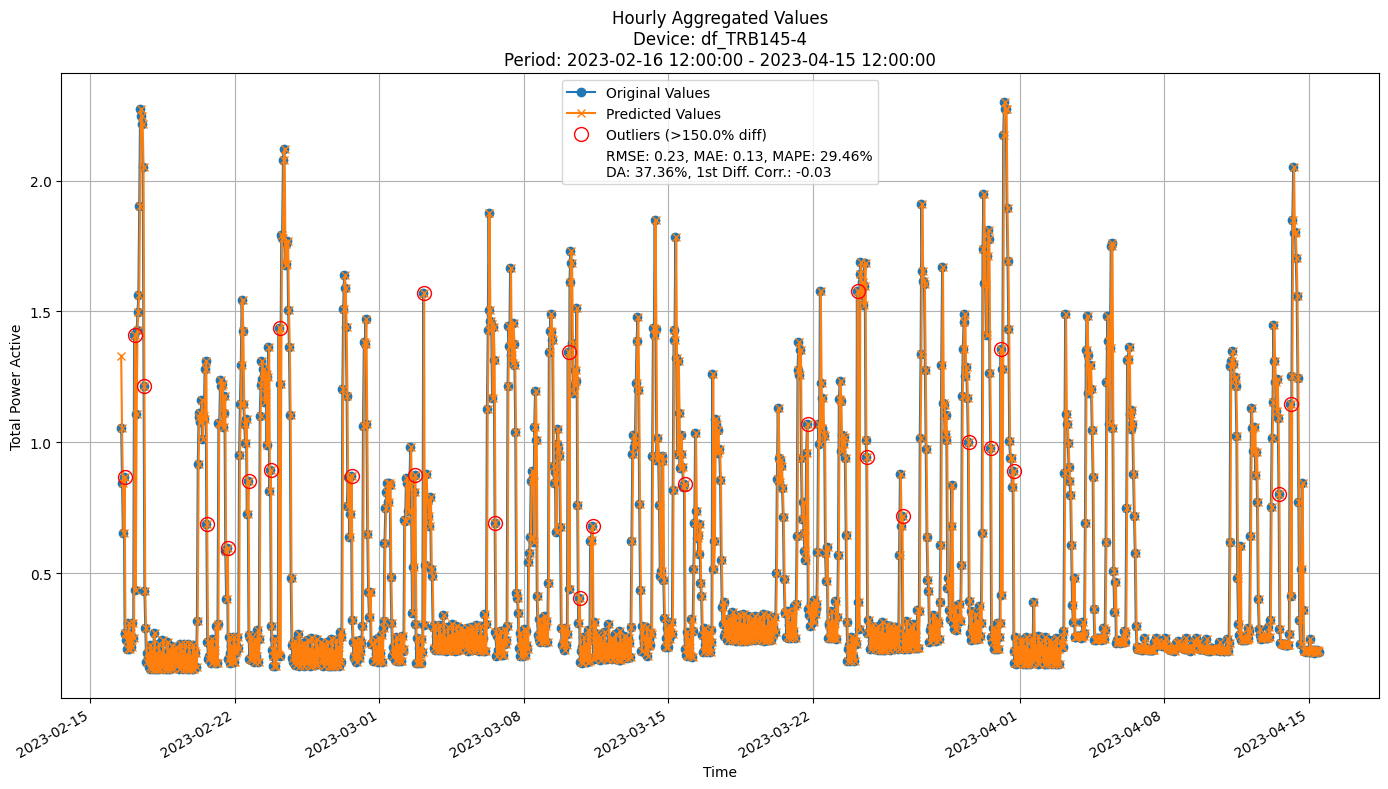

In [9]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [10]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.01,
    subsample=0.8,
    max_depth=6,
    random_state=42)

gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00

Time: 2.57 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-05 13:00:00

Time: 3.40 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3107
	MAE: 0.2115
	MAPE: 25.9946%
	Directional Accuracy: 59.0909%
	First-Diff Correlation: 0.2949
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.9004
	MAE: 3.2685
	MAPE: 18.0613%
	Directional Accuracy: 95.8333%
	Firs

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00

Time: 4.30 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-29 10:00:00

Time: 6.19 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3102
	MAE: 0.2100
	MAPE: 37.2465%
	Directional Accuracy: 57.0681%
	First-Diff Correlation: 0.3825
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.7330
	MAE: 2.2230
	MAPE: 15.7227%
	Directional Accuracy: 66.6667%
	Firs

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00

Time: 12.23 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-26 09:00:00

Time: 12.78 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2151
	MAE: 0.1434
	MAPE: 32.7558%
	Directional Accuracy: 54.1012%
	First-Diff Correlation: 0.3122
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.5558
	MAE: 1.3130
	MAPE: 13.6994%
	Directional Accuracy: 91.6667%
	Fi

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00

Time: 13.36 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1827
	MAE: 0.1234
	MAPE: 36.4754%
	Directional Accuracy: 55.5102%
	First-Diff Correlation: 0.3983
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.5993
	MAE: 1.4502
	MAPE: 22.4846%
	Directional Accuracy: 90.0000%
	First-Diff Correlation: 0.9916
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7.3130
	MAE: 7.3081
	MAPE: 14.1528%
	Directional Accuracy: 100.0000%
	First-Di

#### Results

In [11]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1531 ± 0.0230
	MAE: 0.1075 ± 0.0141
	MAPE: 22.6987% ± 3.6098%
	Dir Accuracy: 73.5020% ± 2.4688%
	First-Diff Correlation: 0.8340 ± 0.0623
Daily Metrics:
	RMSE: 1.3858 ± 0.1691
	MAE: 1.0501 ± 0.1575
	MAPE: 9.5009% ± 1.3033%
	Dir Accuracy: 91.0031% ± 3.2689%
	First-Diff Correlation: 0.9935 ± 0.0023
Weekly Metrics:
	RMSE: 4.1856 ± 0.7505
	MAE: 3.2586 ± 0.5963
	MAPE: 5.3137% ± 1.5030%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 11.9473 ± 3.5234
	MAE: 10.3338 ± 2.8792
	MAPE: 4.0453% ± 0.5061%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2504 ± 0.0463
	MAE: 0.1736 ± 0.0332
	MAPE: 40.0318% ± 9.88

#### Feature importance
[WiP] Right now only for the last split and last device

In [12]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', 0.5484391365887257),
 ('hour', 0.08774805696025723),
 ('L2_act_power_lag_1h', 0.08521933233849191),
 ('L2_current_lag_1h', 0.07883212140737896),
 ('L1_app_power_lag_1h', 0.03445617134798537),
 ('L3_react_power_lag_1h', 0.029322257326210723),
 ('month', 0.01588708485520924),
 ('L2_app_power_lag_1h', 0.012241404491120413),
 ('powerfactor3_lag_1h', 0.00870102193946208),
 ('L1_act_power_lag_1h', 0.0067695776167741185),
 ('grid_freq_lag_1h', 0.006194200349359337),
 ('L3_act_power_lag_1h', 0.005845172349816348),
 ('L3_app_power_lag_1h', 0.005563150224138927),
 ('L3_react_power_lag_24h', 0.0054614272206022964),
 ('powerfactor2_lag_24h', 0.005274743190529659),
 ('L2_act_power_lag_24h', 0.00517120274115817),
 ('L3_current_lag_1h', 0.0038829205081952005),
 ('grid_freq_lag_24h', 0.0038216117745582803),
 ('weekday', 0.0034989313321583094),
 ('powerfactor1_lag_1h', 0.0034510837377848616),
 ('L2_app_power_lag_24h', 0.0033883989105568664),
 ('L1_app_power_lag_24h', 0.0033755392

#### Training plots

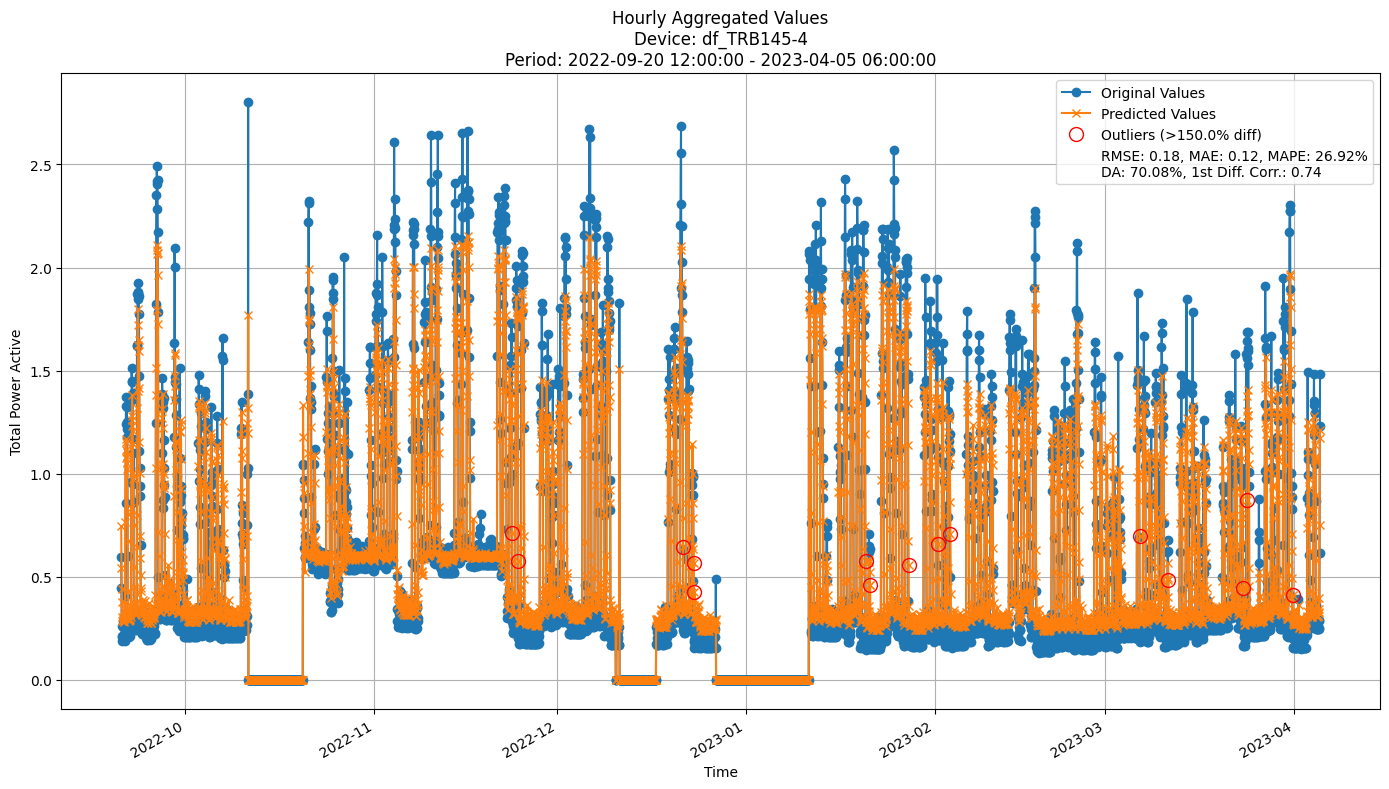

In [13]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

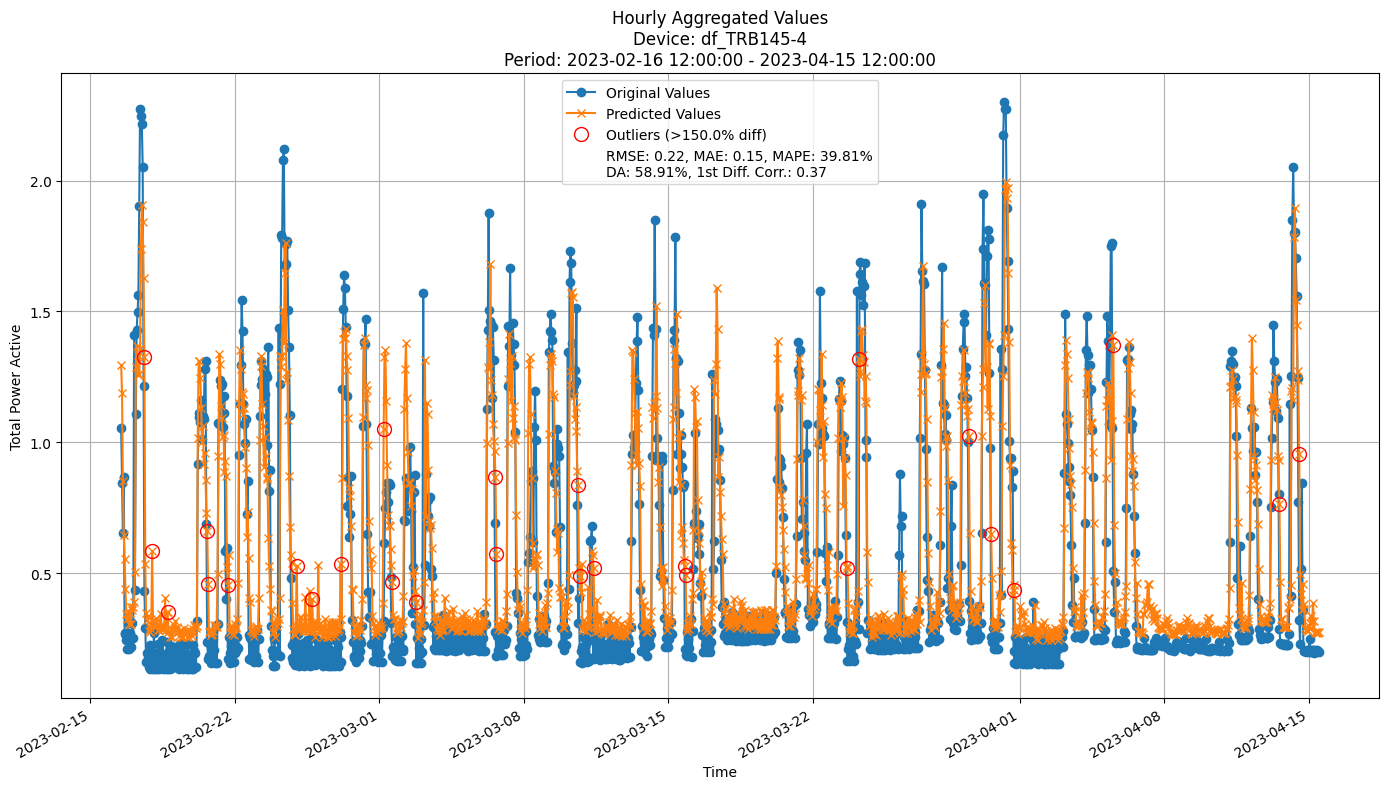

In [14]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# 0.22, 0.15, 39.79, 60.39%, 0.39

### Random Forest model

In [15]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=4,
    max_features=0.8,
    random_state=42, 
    n_jobs=-1)

rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00

Time: 0.15 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-05 13:00:00

Time: 0.15 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2941
	MAE: 0.1899
	MAPE: 22.8102%
	Directional Accuracy: 55.9441%
	First-Diff Correlation: 0.3067
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.2466
	MAE: 2.7325
	MAPE: 14.3043%
	Directional Accuracy: 95.8333%
	Firs

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00

Time: 0.18 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-29 10:00:00

Time: 0.20 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2960
	MAE: 0.1777
	MAPE: 28.0179%
	Directional Accuracy: 50.0873%
	First-Diff Correlation: 0.3477
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.2402
	MAE: 1.7545
	MAPE: 11.2352%
	Directional Accuracy: 70.8333%
	Firs

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00

Time: 0.53 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-26 09:00:00

Time: 0.50 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2243
	MAE: 0.1365
	MAPE: 28.6518%
	Directional Accuracy: 54.4503%
	First-Diff Correlation: 0.3443
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.6912
	MAE: 1.3223
	MAPE: 11.8729%
	Directional Accuracy: 95.8333%
	Firs

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00

Time: 0.55 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.1833
	MAE: 0.0992
	MAPE: 24.9733%
	Directional Accuracy: 50.2041%
	First-Diff Correlation: 0.4345
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 1.4679
	MAE: 1.2499
	MAPE: 14.6646%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 0.9897
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 6.8663
	MAE: 6.7225
	MAPE: 12.2363%
	Directional Accuracy: 100.0000%
	First-Di

#### Results

In [16]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2310 ± 0.0151
	MAE: 0.1348 ± 0.0085
	MAPE: 23.8276% ± 2.3696%
	Dir Accuracy: 56.3230% ± 4.4004%
	First-Diff Correlation: 0.4684 ± 0.0392
Daily Metrics:
	RMSE: 1.6001 ± 0.1665
	MAE: 1.1284 ± 0.1527
	MAPE: 8.6969% ± 0.8364%
	Dir Accuracy: 90.6951% ± 3.3759%
	First-Diff Correlation: 0.9816 ± 0.0048
Weekly Metrics:
	RMSE: 5.5301 ± 1.1260
	MAE: 4.1318 ± 0.8474
	MAPE: 5.9530% ± 1.3681%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 15.2401 ± 5.3636
	MAE: 12.8949 ± 4.2268
	MAPE: 4.8088% ± 0.7902%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2310 ± 0.0151
	MAE: 0.1348 ± 0.0085
	MAPE: 23.8276% ± 2.36

#### Feature importance
[WiP] Right now only for the last split and last device

In [17]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', 0.5073107665187547),
 ('L1_app_power_lag_1h', 0.1383664239600207),
 ('L2_current_lag_1h', 0.07699404649519301),
 ('L2_act_power_lag_1h', 0.0761183904466971),
 ('hour', 0.06923008425325036),
 ('L1_act_power_lag_1h', 0.04902855855253676),
 ('L3_react_power_lag_1h', 0.03307997925626691),
 ('L2_app_power_lag_1h', 0.020779719649149986),
 ('month', 0.004830057670620332),
 ('L3_act_power_lag_1h', 0.00241990387918767),
 ('L1_app_power_lag_24h', 0.002240504681186948),
 ('L3_app_power_lag_1h', 0.0021422042000444246),
 ('powerfactor3_lag_24h', 0.0019034947580848735),
 ('L1_act_power_lag_24h', 0.0018311420279624488),
 ('L2_act_power_lag_24h', 0.0016764755857328613),
 ('powerfactor3_lag_1h', 0.0014549655559809587),
 ('L1_current_lag_24h', 0.0013026463398534327),
 ('L2_current_lag_24h', 0.0012886479318270196),
 ('grid_freq_lag_1h', 0.001036583533245604),
 ('L3_react_power_lag_24h', 0.0008347901383214483),
 ('L3_act_power_lag_24h', 0.0007449161884255651),
 ('L1_react_power_lag_

#### Training plots
Plot only the last period of predictions

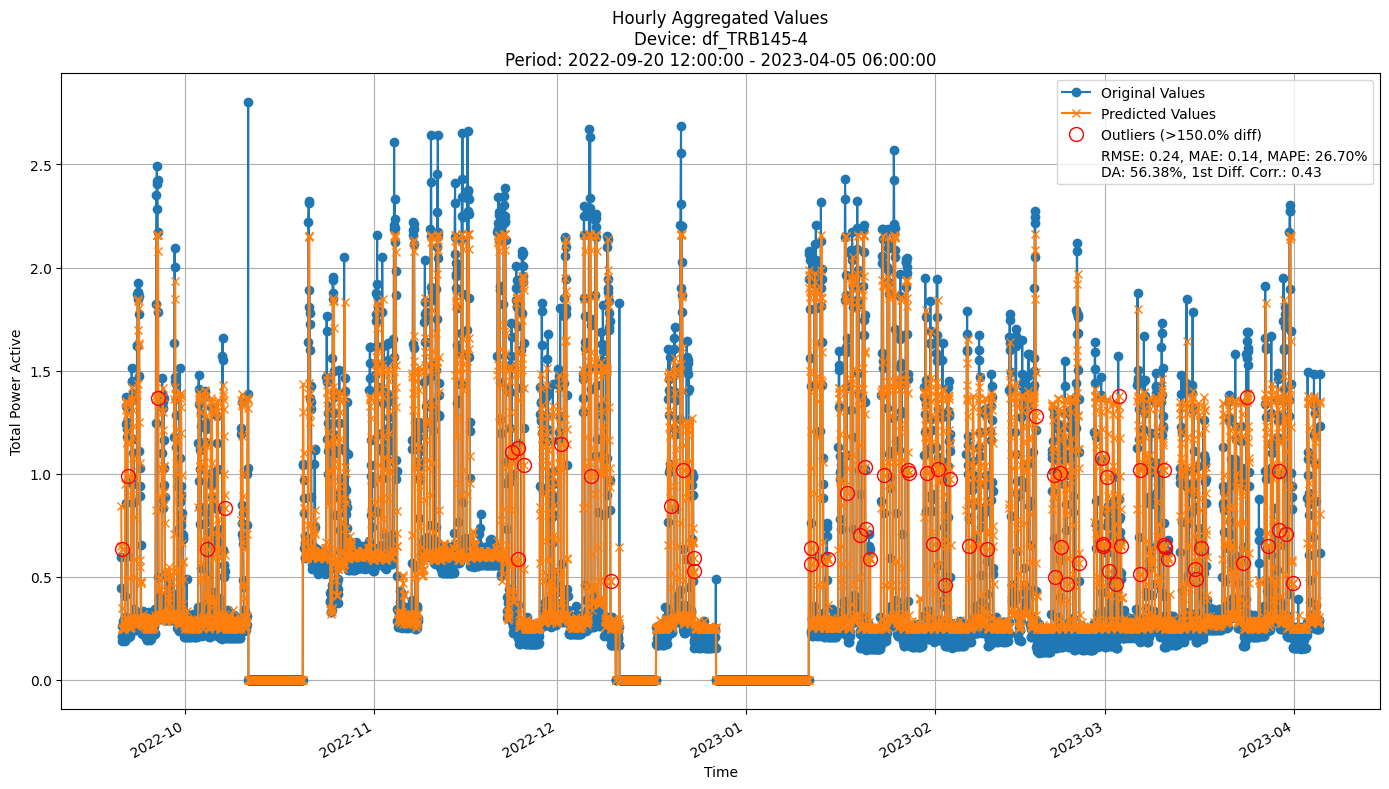

In [18]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

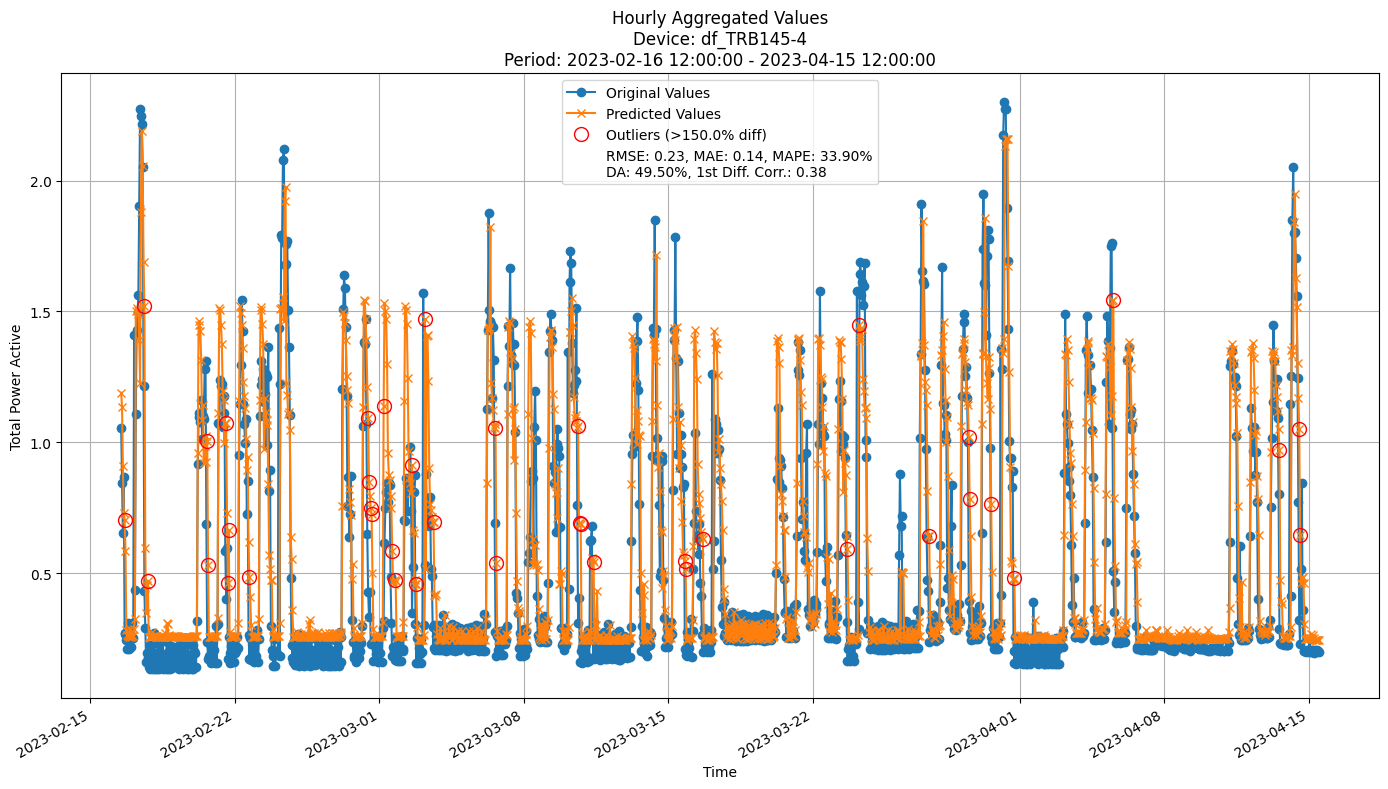

In [19]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [20]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )

hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3978
	MAE: 0.2563
	MAPE: 27.4439%
	Directional Accuracy: 47.5524%
	First-Diff Correlation: 0.1595
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.0512
	MAE: 3.8291
	MAPE: 19.4116%
	Directional Accuracy: 70.8333%
	First-Diff Correlation: 0.8964
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 19.7146
	MAE: 16.4973
	MAPE: 18.1313%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4032
	MAE: 0.2650
	MAPE: 39.9377%
	Directional Accuracy: 50.2618%
	First-Diff Correlation: 0.2158
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.3860
	MAE: 3.2684
	MAPE: 20.1893%
	Directional Accuracy: 50.0000%
	First-Diff Correlation: 0.8460
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.5249
	MAE: 6.8162
	MAPE: 6.3368%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3195
	MAE: 0.2023
	MAPE: 42.2304%
	Directional Accuracy: 42.9319%
	First-Diff Correlation: 0.1999
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.2725
	MAE: 2.3390
	MAPE: 18.2403%
	Directional Accuracy: 58.3333%
	First-Diff Correlation: 0.7902
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 8.9007
	MAE: 7.3824
	MAPE: 12.9930%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2840
	MAE: 0.1644
	MAPE: 42.0583%
	Directional Accuracy: 50.2041%
	First-Diff Correlation: 0.2272
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.6981
	MAE: 1.9824
	MAPE: 24.2623%
	Directional Accuracy: 90.0000%
	First-Diff Correlation: 0.9323
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 10.9288
	MAE: 10.9032
	MAPE: 20.5693%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

#### Results

In [21]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3150 ± 0.0867
	MAE: 0.2003 ± 0.0659
	MAPE: 36.8348% ± 14.9310%
	Dir Accuracy: 39.7363% ± 7.9271%
	First-Diff Correlation: 0.3416 ± 0.1091
Daily Metrics:
	RMSE: 3.0778 ± 1.4050
	MAE: 2.2249 ± 1.0467
	MAPE: 17.5757% ± 10.0102%
	Dir Accuracy: 80.5341% ± 3.2742%
	First-Diff Correlation: 0.8956 ± 0.0900
Weekly Metrics:
	RMSE: 11.4314 ± 6.7043
	MAE: 8.5660 ± 4.9220
	MAPE: 12.4922% ± 7.8378%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 31.5977 ± 14.2935
	MAE: 26.4467 ± 11.6237
	MAPE: 10.9120% ± 7.6103%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3360 ± 0.0475
	MAE: 0.2119 ± 0.0361
	MAPE: 40.7269

#### Training plots
Plot only the last period of predictions

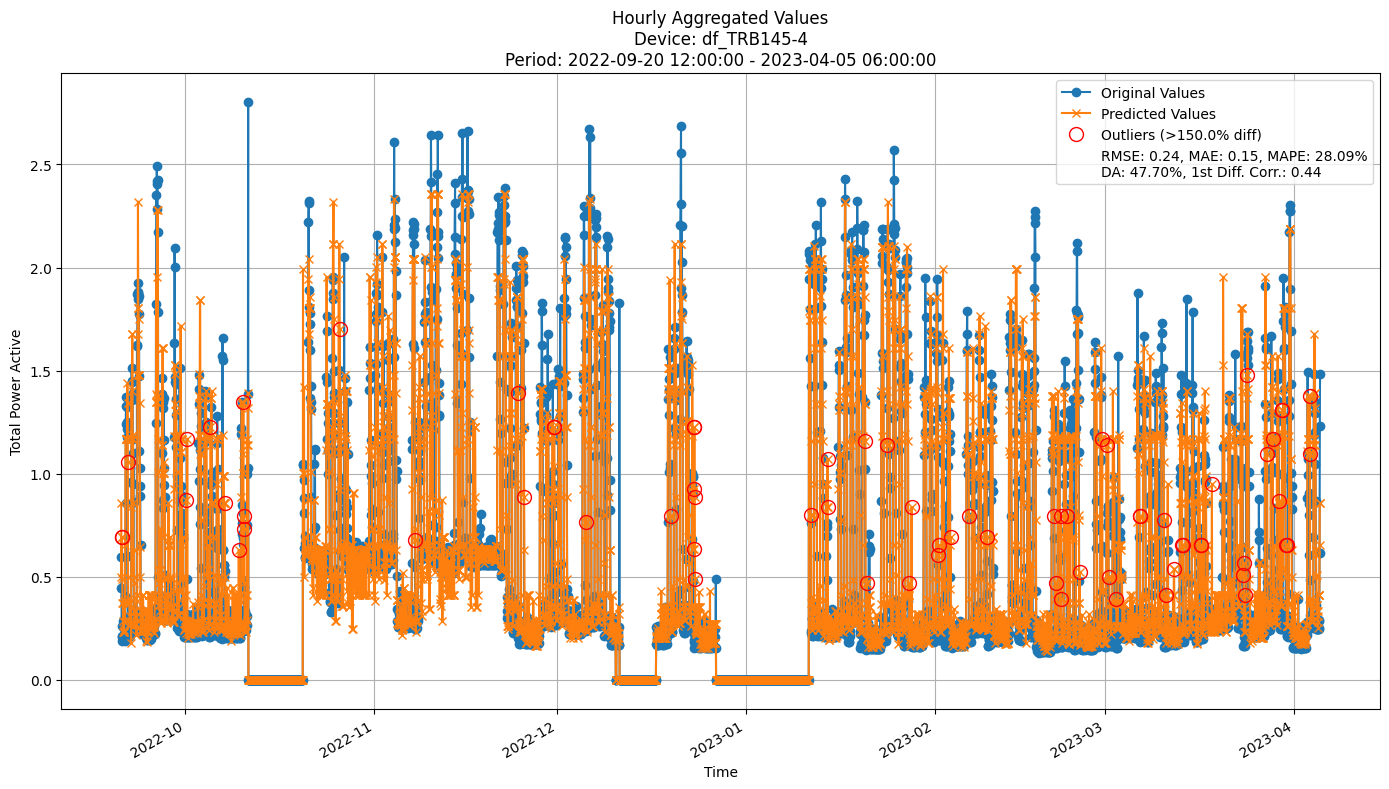

In [22]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

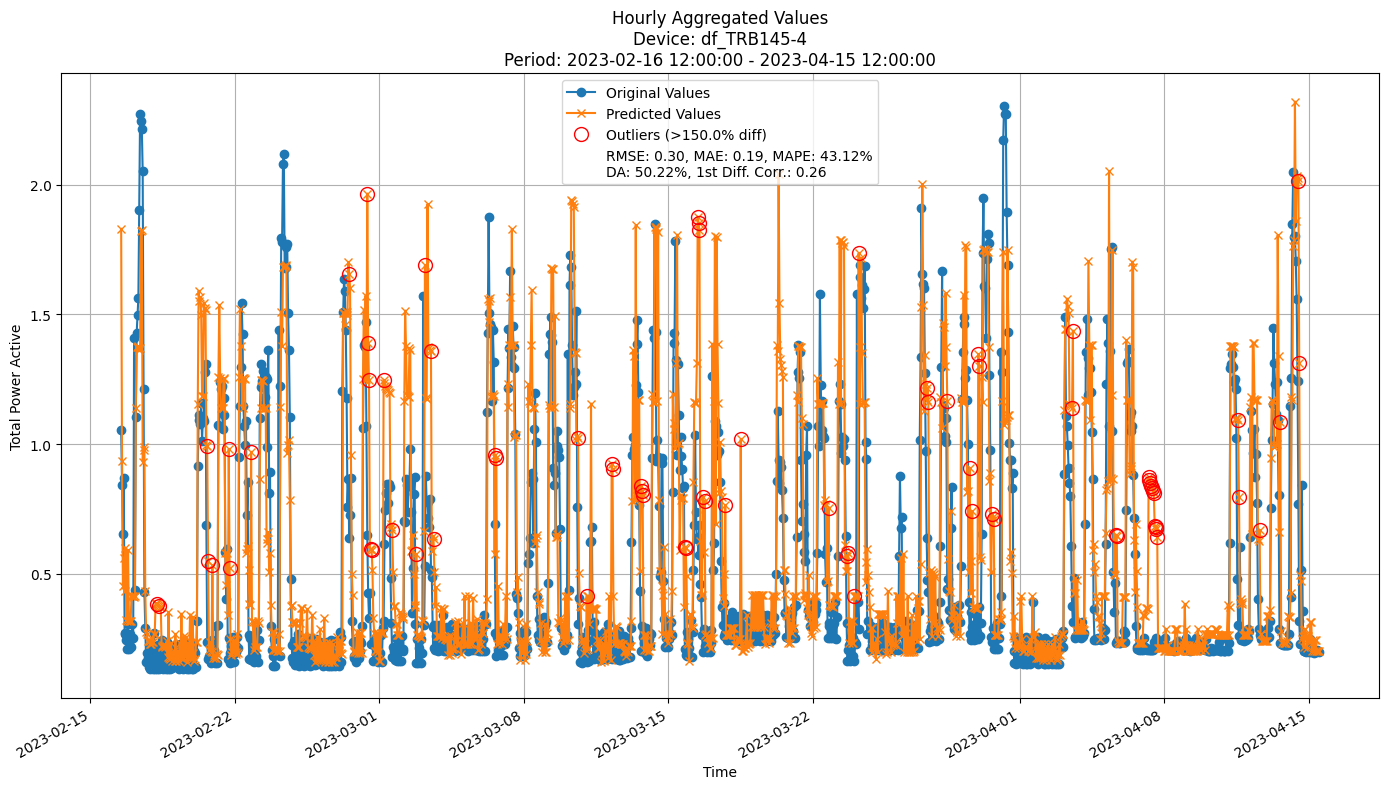

In [23]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [24]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3405
	MAE: 0.2352
	MAPE: 31.8058%
	Directional Accuracy: 49.8252%
	First-Diff Correlation: 0.2879
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.4627
	MAE: 3.5760
	MAPE: 21.2698%
	Directional Accuracy: 83.3333%
	First-Diff Correlation: 0.8712
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.1615
	MAE: 7.3178
	MAPE: 7.9868%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3442
	MAE: 0.2426
	MAPE: 45.5051%
	Directional Accuracy: 56.5445%
	First-Diff Correlation: 0.3846
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 3.9387
	MAE: 3.1826
	MAPE: 24.6583%
	Directional Accuracy: 75.0000%
	First-Diff Correlation: 0.9157
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 7.5235
	MAE: 6.8211
	MAPE: 6.0410%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2483
	MAE: 0.1708
	MAPE: 39.8397%
	Directional Accuracy: 51.8325%
	First-Diff Correlation: 0.3053
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.6744
	MAE: 2.2453
	MAPE: 21.5807%
	Directional Accuracy: 83.3333%
	First-Diff Correlation: 0.9384
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 11.2729
	MAE: 9.6010
	MAPE: 23.3047%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
------------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2191
	MAE: 0.1486
	MAPE: 43.0197%
	Directional Accuracy: 55.9184%
	First-Diff Correlation: 0.4527
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 2.6913
	MAE: 2.3371
	MAPE: 30.6646%
	Directional Accuracy: 80.0000%
	First-Diff Correlation: 0.9751
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 13.0285
	MAE: 12.8538
	MAPE: 23.6569%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

#### Results

In [25]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2768 ± 0.0723
	MAE: 0.1890 ± 0.0713
	MAPE: 40.8739% ± 22.0890%
	Dir Accuracy: 55.9934% ± 9.1942%
	First-Diff Correlation: 0.4715 ± 0.1300
Daily Metrics:
	RMSE: 3.0736 ± 1.2041
	MAE: 2.3295 ± 0.9760
	MAPE: 21.0970% ± 12.2377%
	Dir Accuracy: 84.2771% ± 3.9899%
	First-Diff Correlation: 0.9140 ± 0.1058
Weekly Metrics:
	RMSE: 13.1930 ± 5.6795
	MAE: 10.4141 ± 5.2370
	MAPE: 15.1541% ± 8.3721%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 39.7904 ± 14.7552
	MAE: 31.8433 ± 11.1681
	MAPE: 12.5762% ± 7.5757%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2814 ± 0.0431
	MAE: 0.1948 ± 0.0314
	MAPE: 44.679

#### Training plots

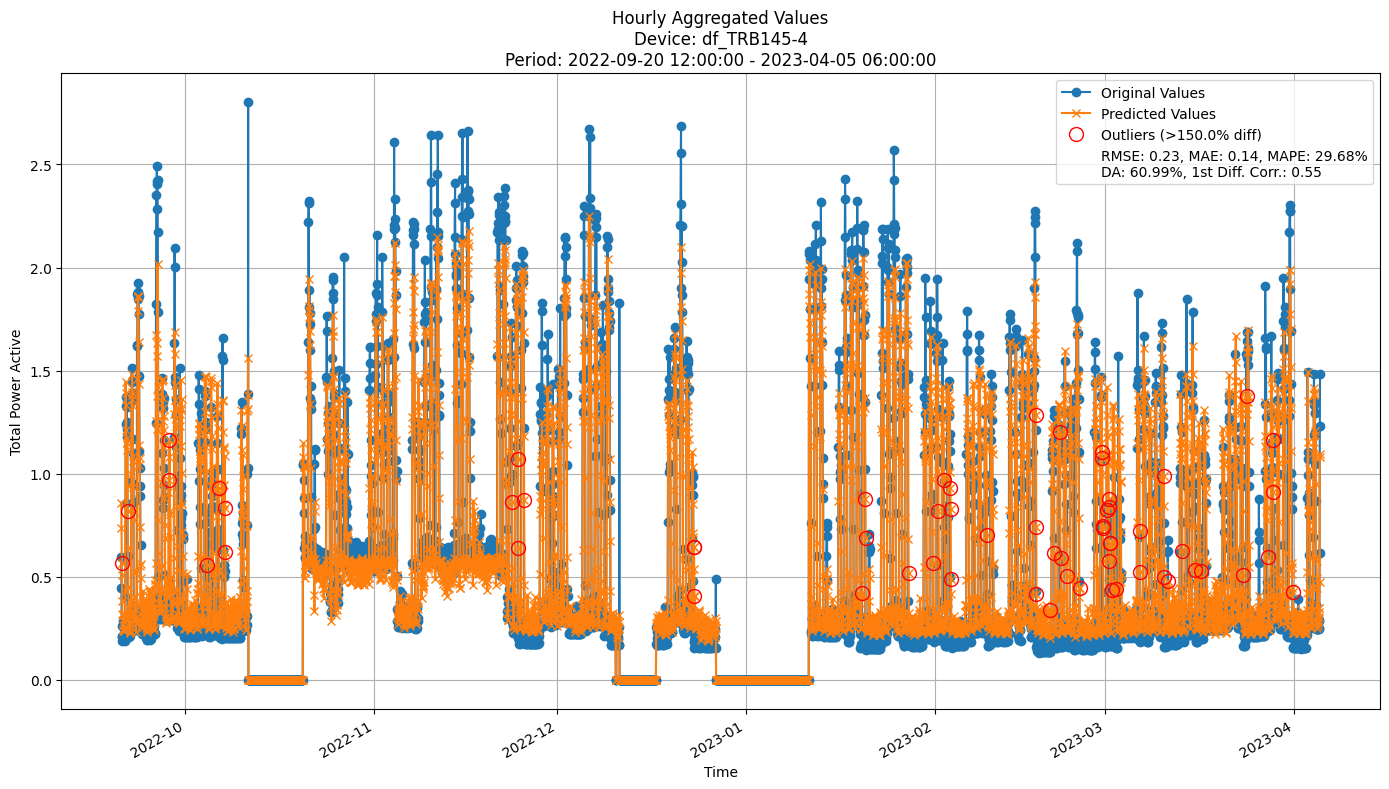

In [26]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

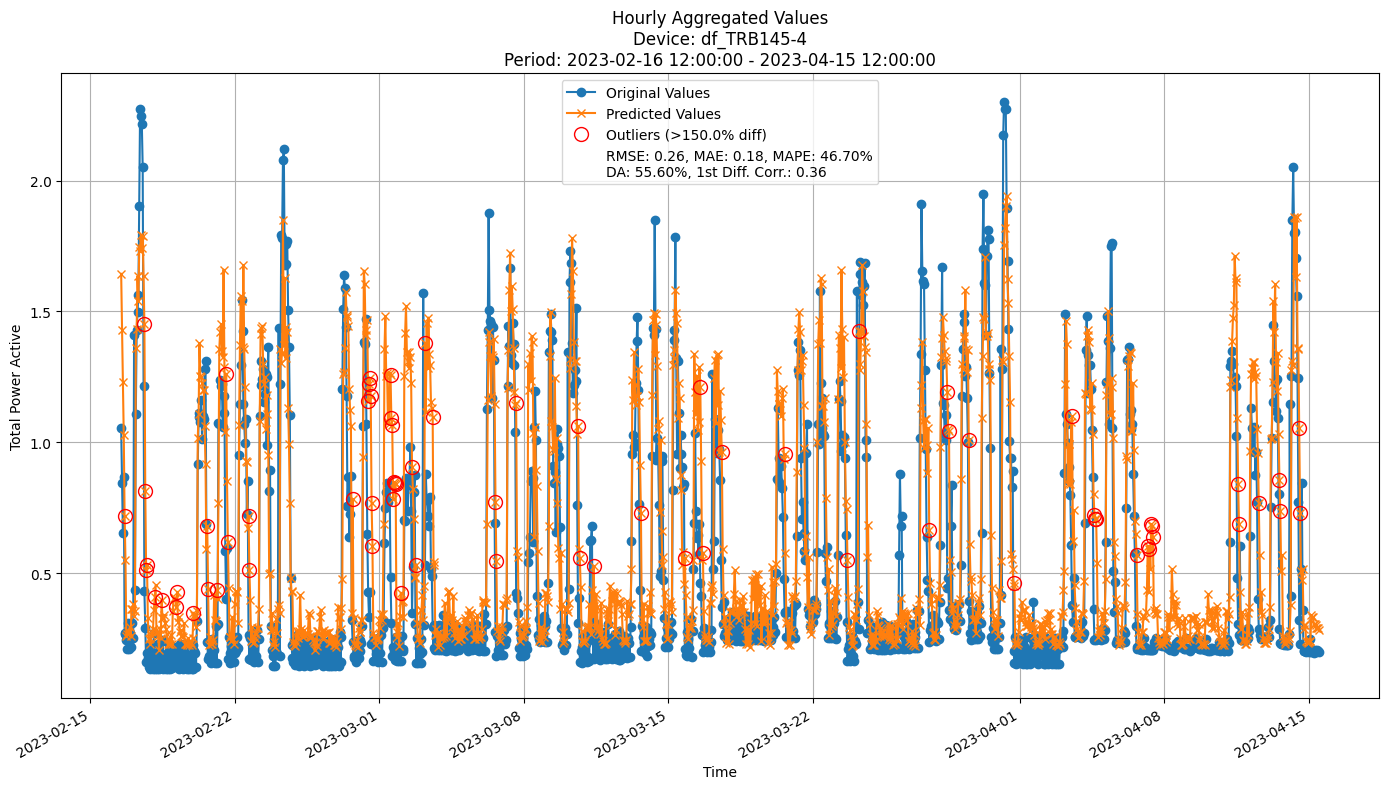

In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.001
depth = 100
eagerness = 100
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf',
        eagerness = eagerness,
        grace_period_depth = -1
    )

fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5364
	MAE: 0.3770
	MAPE: 42.5632%
	Directional Accuracy: 43.7063%
	First-Diff Correlation: 0.0514
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.7617
	MAE: 7.1675
	MAPE: 36.3860%
	Directional Accuracy: 58.3333%
	First-Diff Correlation: 0.3697
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 31.2159
	MAE: 26.9138
	MAPE: 26.8513%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5872
	MAE: 0.4448
	MAPE: 78.7355%
	Directional Accuracy: 48.3421%
	First-Diff Correlation: 0.1809
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.4843
	MAE: 7.0895
	MAPE: 55.0140%
	Directional Accuracy: 37.5000%
	First-Diff Correlation: 0.3728
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 20.8676
	MAE: 18.7968
	MAPE: 16.5493%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3954
	MAE: 0.2985
	MAPE: 91.5855%
	Directional Accuracy: 52.1815%
	First-Diff Correlation: 0.1114
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 5.8967
	MAE: 4.4606
	MAPE: 62.6950%
	Directional Accuracy: 54.1667%
	First-Diff Correlation: 0.4426
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 19.5398
	MAE: 16.6106
	MAPE: 61.1497%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4444
	MAE: 0.3446
	MAPE: 131.3779%
	Directional Accuracy: 52.2449%
	First-Diff Correlation: 0.1208
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.3320
	MAE: 5.9109
	MAPE: 112.7394%
	Directional Accuracy: 60.0000%
	First-Diff Correlation: 0.6632
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 29.8703
	MAE: 29.2000
	MAPE: 59.0319%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
---------------------------------

#### Results

In [29]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4917 ± 0.0238
	MAE: 0.3714 ± 0.0267
	MAPE: 83.0102% ± 10.9991%
	Dir Accuracy: 18.1568% ± 3.7919%
	First-Diff Correlation: 0.1340 ± 0.0602
Daily Metrics:
	RMSE: 6.9276 ± 0.5670
	MAE: 5.1945 ± 0.6424
	MAPE: 50.6035% ± 7.5651%
	Dir Accuracy: 25.5720% ± 7.4186%
	First-Diff Correlation: 0.3202 ± 0.1064
Weekly Metrics:
	RMSE: 20.8392 ± 3.9335
	MAE: 17.2504 ± 3.6918
	MAPE: 29.1167% ± 8.6692%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 62.5837 ± 19.9872
	MAE: 55.1788 ± 17.9404
	MAPE: 21.7781% ± 2.4524%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4906 ± 0.0693
	MAE: 0.3792 ± 0.0560
	MAPE: 104.562

#### Training plots


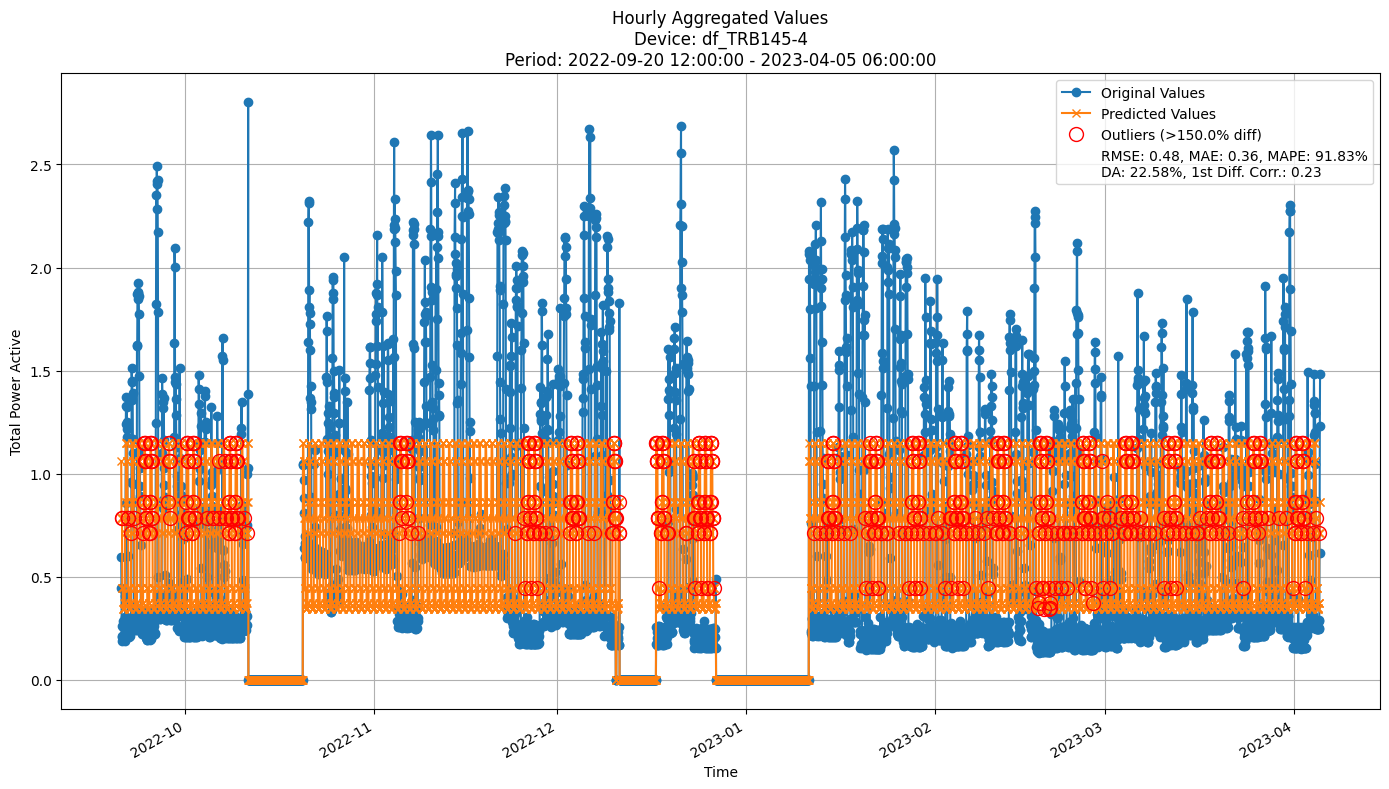

In [30]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

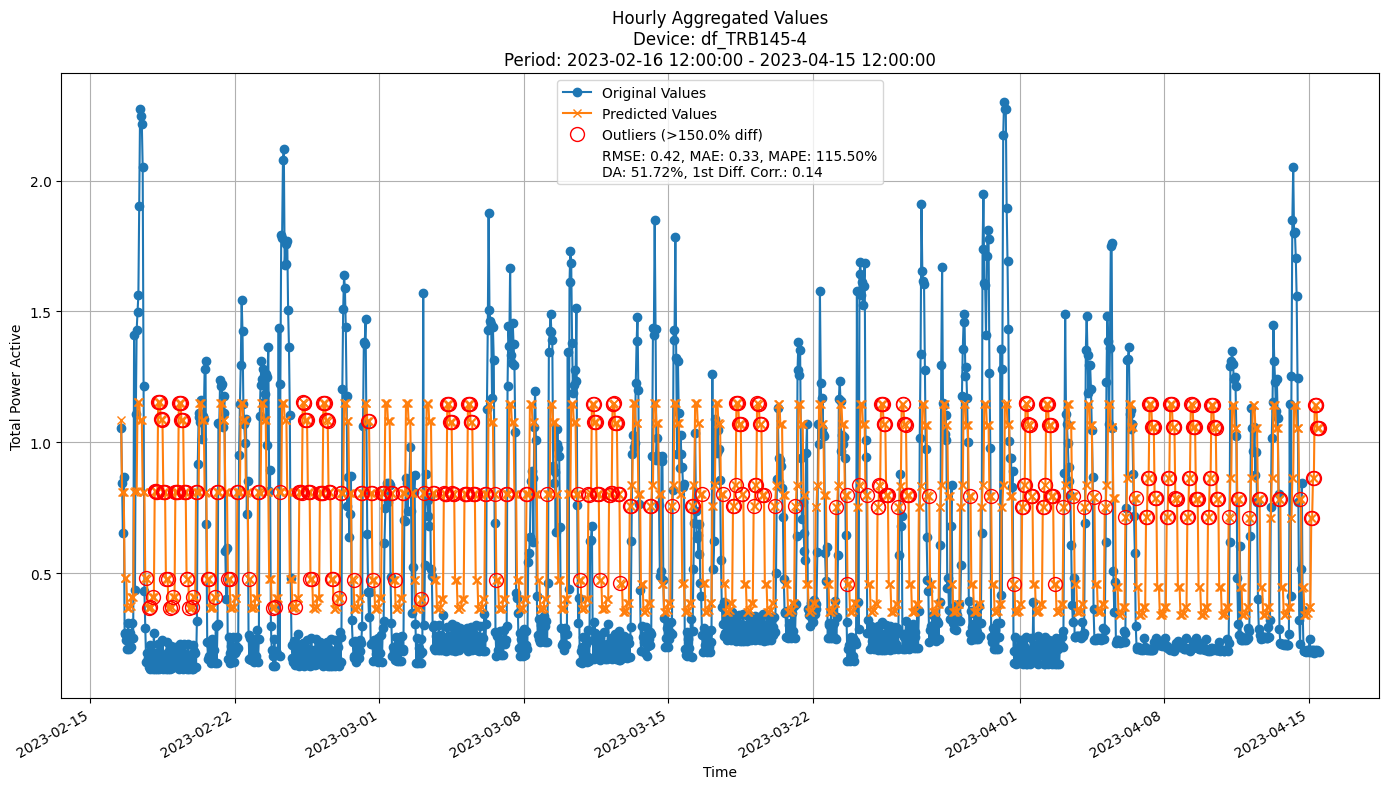

In [31]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [32]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )

arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4592
	MAE: 0.3142
	MAPE: 38.5545%
	Directional Accuracy: 55.4196%
	First-Diff Correlation: 0.3380
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.1083
	MAE: 6.0187
	MAPE: 34.6629%
	Directional Accuracy: 66.6667%
	First-Diff Correlation: 0.6704
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 20.3596
	MAE: 18.5061
	MAPE: 23.7317%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4853
	MAE: 0.3900
	MAPE: 82.1247%
	Directional Accuracy: 61.7801%
	First-Diff Correlation: 0.4603
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 6.3988
	MAE: 5.0633
	MAPE: 45.2252%
	Directional Accuracy: 45.8333%
	First-Diff Correlation: 0.6488
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 9.7670
	MAE: 8.6190
	MAPE: 7.7479%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
--------------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3060
	MAE: 0.2520
	MAPE: 73.3565%
	Directional Accuracy: 57.9407%
	First-Diff Correlation: 0.4416
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.1521
	MAE: 3.3246
	MAPE: 43.5886%
	Directional Accuracy: 75.0000%
	First-Diff Correlation: 0.8014
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 14.5029
	MAE: 11.0169
	MAPE: 48.1252%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.2890
	MAE: 0.2532
	MAPE: 90.2062%
	Directional Accuracy: 55.5102%
	First-Diff Correlation: 0.4728
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 4.3785
	MAE: 3.8226
	MAPE: 65.5164%
	Directional Accuracy: 60.0000%
	First-Diff Correlation: 0.9178
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 18.8501
	MAE: 18.5905
	MAPE: 37.1605%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

#### Results

In [33]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4178 ± 0.0182
	MAE: 0.3192 ± 0.0355
	MAPE: 72.8019% ± 13.2936%
	Dir Accuracy: 59.5332% ± 1.0553%
	First-Diff Correlation: 0.4143 ± 0.0626
Daily Metrics:
	RMSE: 5.7523 ± 0.4578
	MAE: 4.2675 ± 0.6031
	MAPE: 41.3560% ± 7.4743%
	Dir Accuracy: 78.6655% ± 5.9134%
	First-Diff Correlation: 0.7196 ± 0.0559
Weekly Metrics:
	RMSE: 21.1960 ± 3.9991
	MAE: 16.4159 ± 2.8600
	MAPE: 26.2009% ± 5.1302%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 65.0272 ± 20.6240
	MAE: 50.6920 ± 13.6165
	MAPE: 20.6085% ± 3.7344%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000

\Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3963 ± 0.0758
	MAE: 0.3306 ± 0.0648
	MAPE: 95.1352

#### Training plots


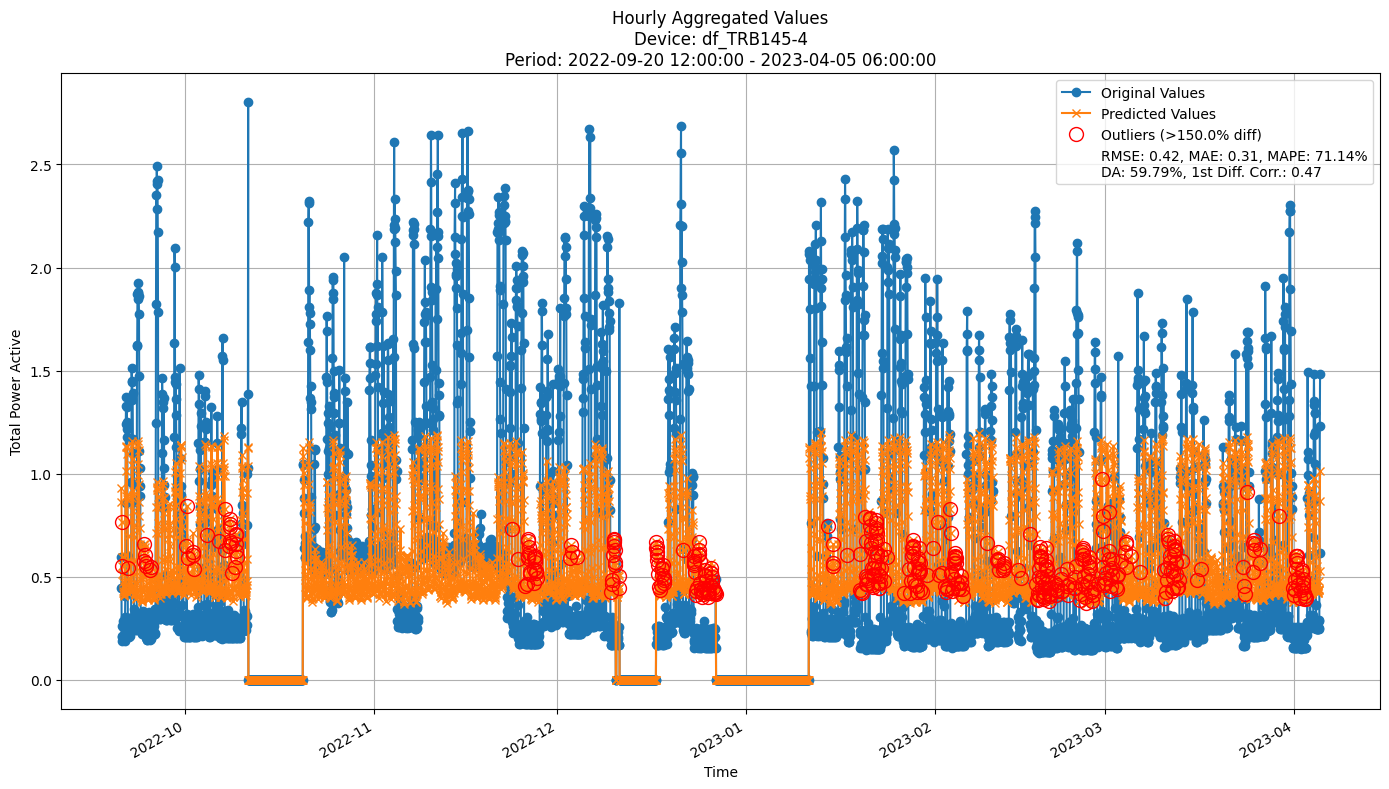

In [34]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

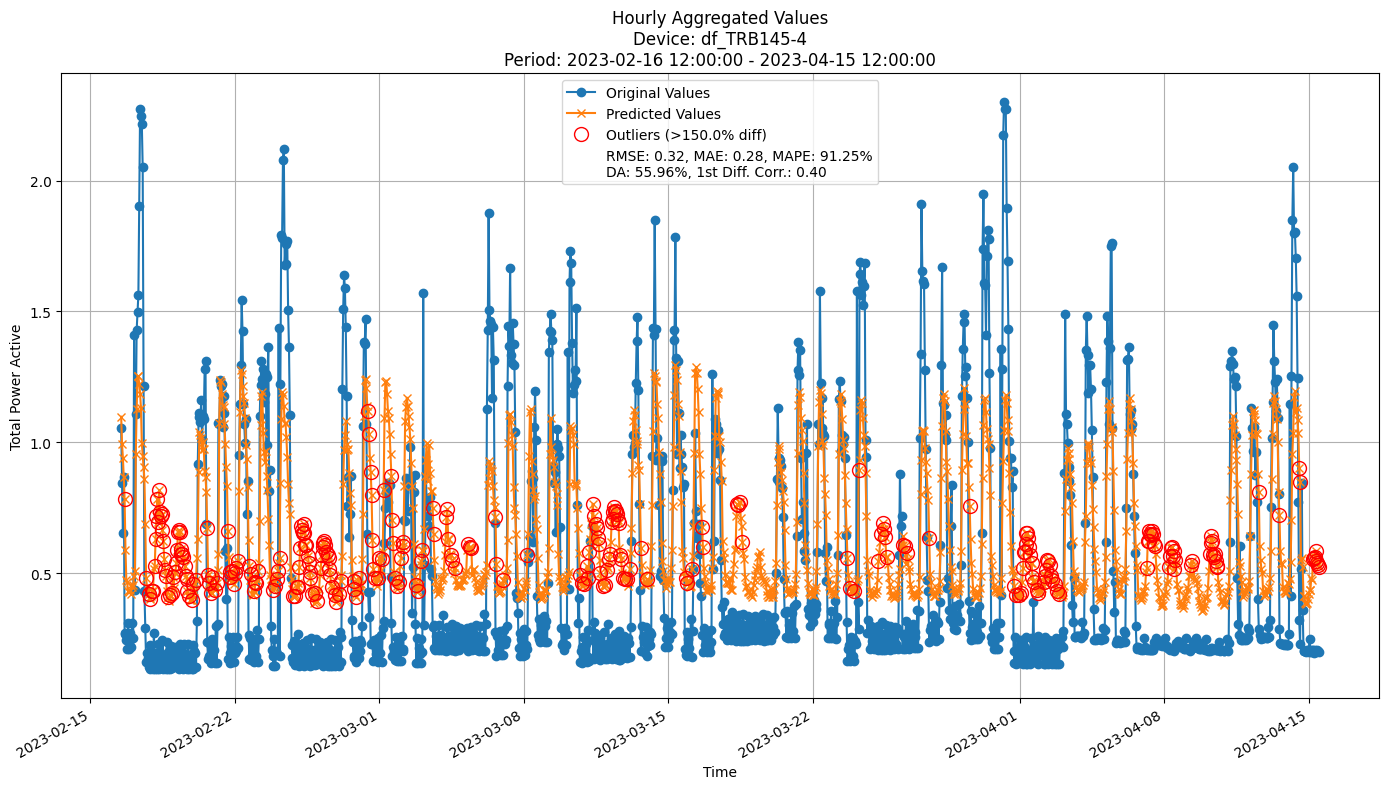

In [35]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [36]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.001
n_trees = 10
depth = 100
grace_period = 10
max_feature = 1.0
eagerness = 1000
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence, "hf", max_features, eagerness, grace_period_depth),
    verbose=False
    )

incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5116
	MAE: 0.3586
	MAPE: 41.5663%
	Directional Accuracy: 42.3077%
	First-Diff Correlation: 0.2787
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.4137
	MAE: 6.9688
	MAPE: 36.0900%
	Directional Accuracy: 58.3333%
	First-Diff Correlation: 0.3685
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 28.0689
	MAE: 23.7815
	MAPE: 22.9790%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.5703
	MAE: 0.4331
	MAPE: 79.8495%
	Directional Accuracy: 48.3421%
	First-Diff Correlation: 0.3517
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 8.3387
	MAE: 6.9229
	MAPE: 55.9901%
	Directional Accuracy: 33.3333%
	First-Diff Correlation: 0.3728
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 18.5064
	MAE: 17.1956
	MAPE: 15.2526%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.3935
	MAE: 0.2949
	MAPE: 93.5487%
	Directional Accuracy: 47.8185%
	First-Diff Correlation: 0.3284
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 6.2578
	MAE: 4.8573
	MAPE: 67.5193%
	Directional Accuracy: 54.1667%
	First-Diff Correlation: 0.4460
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 22.9943
	MAE: 19.7077
	MAPE: 65.6016%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
-----------------------------------

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
	RMSE: 0.4579
	MAE: 0.3483
	MAPE: 136.9921%
	Directional Accuracy: 49.3878%
	First-Diff Correlation: 0.2279
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
	RMSE: 7.7691
	MAE: 6.3538
	MAPE: 119.9136%
	Directional Accuracy: 60.0000%
	First-Diff Correlation: 0.6493
--------------------------------------------------
Weekly Metrics:
--------------------------------------------------
	RMSE: 32.7771
	MAE: 32.2540
	MAPE: 64.6741%
	Directional Accuracy: 100.0000%
	First-Diff Correlation: 1.0000
--------------------------------------------------
28_days Metrics:
---------------------------------

#### Results

In [37]:
print("\n\nTrain period metrics:")
all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4830 ± 0.0226
	MAE: 0.3650 ± 0.0230
	MAPE: 85.3524% ± 10.6071%
	Dir Accuracy: 18.9515% ± 3.3938%
	First-Diff Correlation: 0.2775 ± 0.0817
Daily Metrics:
	RMSE: 6.9431 ± 0.5674
	MAE: 5.2172 ± 0.6377
	MAPE: 52.8866% ± 7.6930%
	Dir Accuracy: 25.5720% ± 7.4186%
	First-Diff Correlation: 0.3228 ± 0.1067
Weekly Metrics:
	RMSE: 21.1862 ± 3.5938
	MAE: 17.2476 ± 3.5277
	MAPE: 30.2928% ± 9.3923%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000
28_days Metrics:
	RMSE: 63.4312 ± 17.5277
	MAE: 55.9525 ± 14.6944
	MAPE: 22.9627% ± 2.1799%
	Dir Accuracy: 100.0000% ± 0.0000%
	First-Diff Correlation: 1.0000 ± 0.0000


Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4844 ± 0.0621
	MAE: 0.3728 ± 0.0545
	MAPE: 106.890

#### Train plots

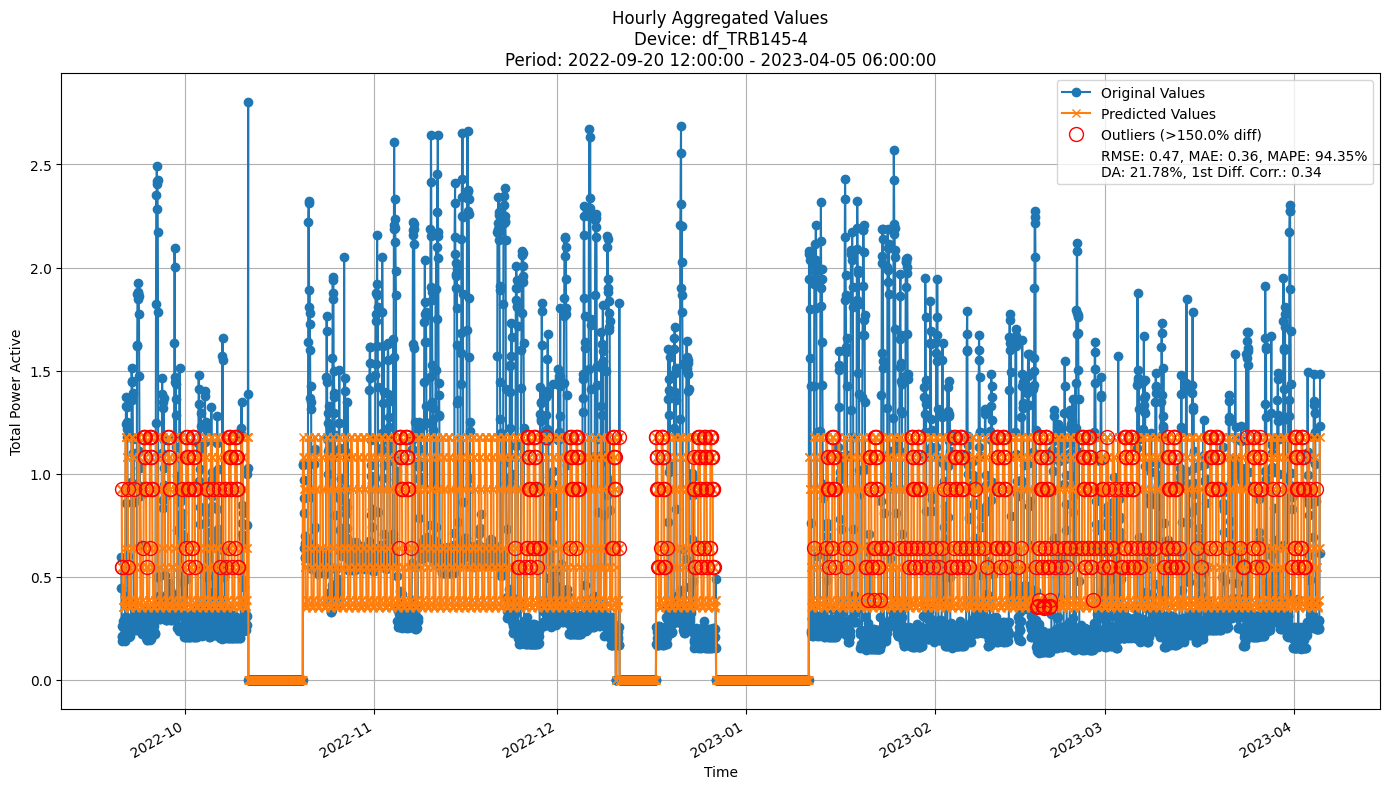

In [38]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

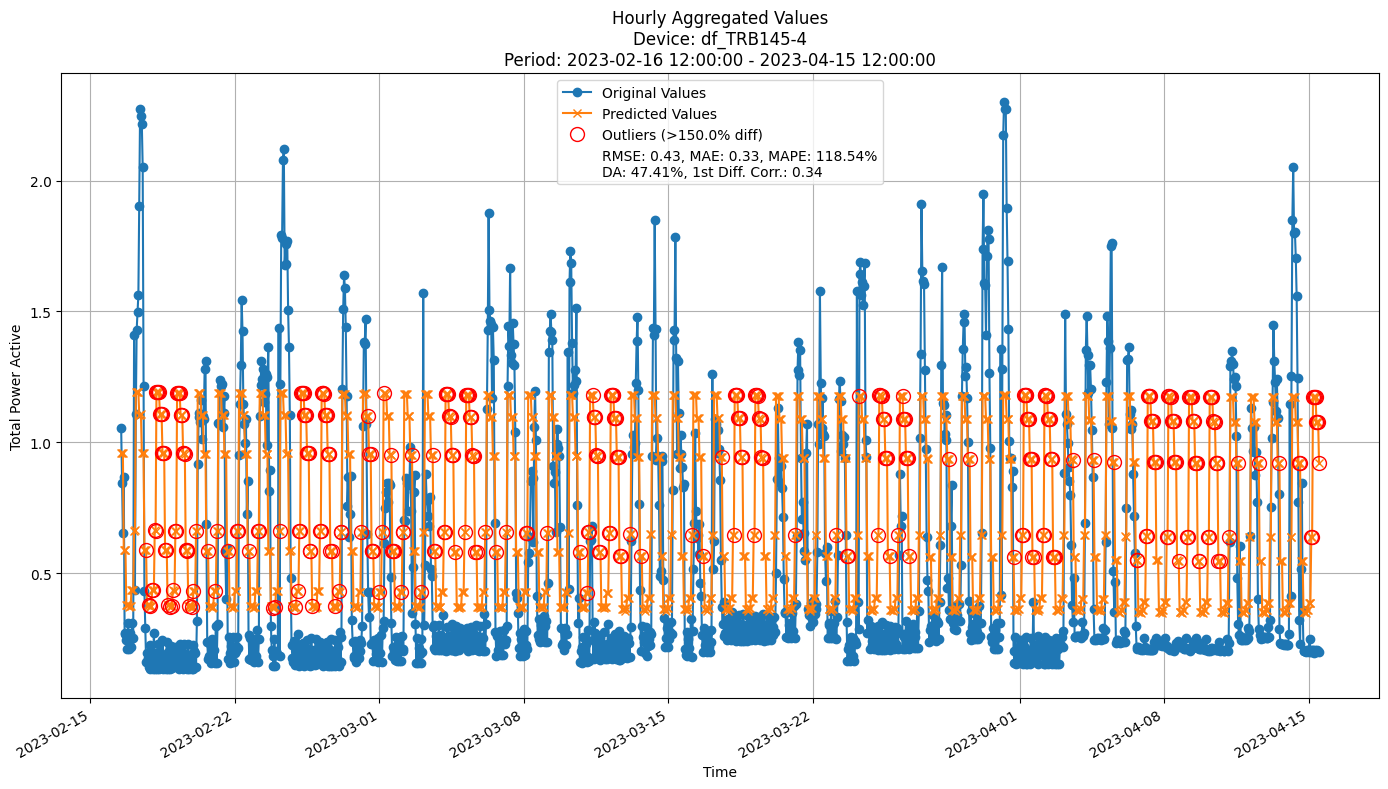

In [39]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

## Model Comparison

### Overall validation results

In [40]:
MODEL_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": all_time_valid_metrics,
}

AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]

device_ids = set()
for m in MODEL_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%)
0,Baseline,0.245 ± 0.028,0.138 ± 0.022,26.419 ± 7.054,36.931 ± 3.102,9.734 ± 13.688
1,GBDT,0.250 ± 0.046,0.174 ± 0.033,40.032 ± 9.884,60.858 ± 5.369,41.307 ± 9.487
2,RandomForest,0.231 ± 0.015,0.135 ± 0.009,23.828 ± 2.370,56.323 ± 4.400,46.842 ± 3.920
3,HoeffdingTree,0.336 ± 0.047,0.212 ± 0.036,40.727 ± 6.967,50.791 ± 4.717,26.805 ± 8.182
4,ARF_Hoeffding,0.281 ± 0.043,0.195 ± 0.031,44.679 ± 7.578,55.724 ± 3.456,40.973 ± 8.841
5,FastODT,0.491 ± 0.069,0.379 ± 0.056,104.562 ± 33.215,49.284 ± 2.902,15.011 ± 5.319
6,ARF_FastODT,0.396 ± 0.076,0.331 ± 0.065,95.135 ± 34.113,58.010 ± 2.781,44.466 ± 6.890
7,IncubationBoost,0.484 ± 0.062,0.373 ± 0.055,106.891 ± 34.964,46.879 ± 2.203,33.622 ± 6.180


### By-period validation results

In [41]:
MODEL_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, model_period_metrics, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        model_period_metrics: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in model_period_metrics.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [42]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=MODEL_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,33.042,59.091,55.944,47.552,49.825,43.706,55.420,42.308,48.361000
Period 2,37.871,57.068,50.087,50.262,56.545,48.342,61.780,48.342,51.287125
Period 3,35.664,68.706,53.322,50.175,56.469,47.028,59.790,45.979,52.141625
Period 4,36.300,66.143,52.531,56.894,60.035,50.262,61.257,48.342,53.970500
Period 5,34.965,65.385,44.406,57.517,59.441,51.224,54.371,45.979,51.661000
Period 6,36.998,54.101,54.450,42.932,51.832,52.182,57.941,47.818,49.781750
Period 7,43.673,55.510,50.204,50.204,55.918,52.245,55.510,49.388,51.581500



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,4.829,-2.023,-5.857,2.710,6.720,4.636,6.360,6.034,2.926
Period 3 - Period 2,-2.207,11.638,3.235,-0.087,-0.076,-1.314,-1.990,-2.363,0.855
Period 4 - Period 3,0.636,-2.563,-0.791,6.719,3.566,3.234,1.467,2.363,1.829
Period 5 - Period 4,-1.335,-0.758,-8.125,0.623,-0.594,0.962,-6.886,-2.363,-2.310
Period 6 - Period 5,2.033,-11.284,10.044,-14.585,-7.609,0.958,3.570,1.839,-1.879
Period 7 - Period 6,6.675,1.409,-4.246,7.272,4.086,0.063,-2.431,1.570,1.800


#### MAPE (lower is better)

In [43]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=MODEL_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.963,25.995,22.810,27.444,31.806,42.563,38.554,41.566,31.087625
Period 2,24.007,37.247,28.018,39.938,45.505,78.735,82.125,79.849,51.928000
Period 3,32.582,58.584,46.030,52.114,54.512,143.052,155.021,146.897,86.099000
Period 4,30.139,40.855,35.336,36.845,42.922,111.995,117.051,113.727,66.108750
Period 5,35.590,48.312,42.981,44.459,55.149,132.628,109.633,135.655,75.550875
Period 6,29.454,32.756,28.652,42.230,39.840,91.586,73.357,93.549,53.928000
Period 7,15.200,36.475,24.973,42.058,43.020,131.378,90.206,136.992,65.037750



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.044,11.252,5.208,12.494,13.699,36.172,43.571,38.283,20.840
Period 3 - Period 2,8.575,21.337,18.012,12.176,9.007,64.317,72.896,67.048,34.171
Period 4 - Period 3,-2.443,-17.729,-10.694,-15.269,-11.590,-31.057,-37.970,-33.170,-19.990
Period 5 - Period 4,5.451,7.457,7.645,7.614,12.227,20.633,-7.418,21.928,9.442
Period 6 - Period 5,-6.136,-15.556,-14.329,-2.229,-15.309,-41.042,-36.276,-42.106,-21.623
Period 7 - Period 6,-14.254,3.719,-3.679,-0.172,3.180,39.792,16.849,43.443,11.110


#### RMSE (lower is better)

In [44]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    model_period_metrics=MODEL_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.260,0.311,0.294,0.398,0.341,0.536,0.459,0.512,0.388875
Period 2,0.267,0.310,0.296,0.403,0.344,0.587,0.485,0.570,0.407750
Period 3,0.271,0.279,0.271,0.362,0.262,0.575,0.479,0.567,0.383250
Period 4,0.246,0.221,0.241,0.288,0.269,0.460,0.401,0.448,0.321750
Period 5,0.251,0.234,0.254,0.297,0.287,0.436,0.354,0.442,0.319375
Period 6,0.237,0.215,0.224,0.320,0.248,0.395,0.306,0.394,0.292375
Period 7,0.182,0.183,0.183,0.284,0.219,0.444,0.289,0.458,0.280250



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.007,-0.001,0.002,0.005,0.003,0.051,0.026,0.058,0.019
Period 3 - Period 2,0.004,-0.031,-0.025,-0.041,-0.082,-0.012,-0.006,-0.003,-0.024
Period 4 - Period 3,-0.025,-0.058,-0.030,-0.074,0.007,-0.115,-0.078,-0.119,-0.061
Period 5 - Period 4,0.005,0.013,0.013,0.009,0.018,-0.024,-0.047,-0.006,-0.002
Period 6 - Period 5,-0.014,-0.019,-0.030,0.023,-0.039,-0.041,-0.048,-0.048,-0.027
Period 7 - Period 6,-0.055,-0.032,-0.041,-0.036,-0.029,0.049,-0.017,0.064,-0.012
